# Stressed vs. Normal Text Classification with an LSTM
A complete supervised binary-classification assignment using the supplied CSV.
**Target:** `normal = 0`, `stressed = 1`. These are dataset labels, not a medical diagnosis.

**Colab:** select Runtime → Change runtime type → T4 GPU if available, then run the
cells in order. CPU also works. Upload the original CSV when prompted in Step 2.
No external embeddings or dataset downloads are needed. The notebook is self-contained.
TensorFlow, pandas, NumPy, scikit-learn and matplotlib must be installed. Colab normally
supplies them; for a local environment use the included requirements.txt.

The supplied file has 1,800 rows, columns `post` and `label`, and 900 examples of each label.
It decodes with cp1252. We audit it, remove ambiguous/duplicate texts, split it, train an
LSTM and a TF-IDF baseline, evaluate once on the held-out test set, then save the model.

## 1. Imports and reproducibility
The seed fixes the data split and random initializations. Exact neural-network results
can still differ across library versions, GPU/CPU kernels and hardware.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import sys
import re
import json
import math
import hashlib
import platform
import shutil
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
)

SEED = 42
MAX_TOKENS = 10000
MAX_LENGTH_CAP = 256
EMBEDDING_DIM = 64
LSTM_UNITS = 64
BATCH_SIZE = 32
EPOCHS = 20
THRESHOLD = 0.5  # fixed before test evaluation; do not tune on the test set
LABEL_MAP = {"normal": 0, "stressed": 1}
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)
keras.utils.set_random_seed(SEED)
print("Python:", platform.python_version(), "TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

Python: 3.12.14 TensorFlow: 2.20.0
GPU devices: []


## 2. Upload and read the CSV
The original file is not UTF-8. Trying UTF-8 followed by cp1252 avoids a
UnicodeDecodeError without silently deleting characters. Unexpected labels or columns
produce an error instead of being guessed. Outside Colab, put the CSV in `data/` or set
the `DATA_PATH` environment variable to its path.

In [2]:
DATA_PATH = os.environ.get("DATA_PATH", "").strip()
if not DATA_PATH:
    candidates = sorted(set(Path(".").glob("*.csv")) | set(Path("data").glob("*.csv")))
    if len(candidates) == 1:
        DATA_PATH = str(candidates[0])
    elif len(candidates) > 1:
        raise ValueError("Several CSV files found. Set DATA_PATH to the intended dataset.")
    else:
        try:
            from google.colab import files
        except ImportError as exc:
            raise FileNotFoundError("Put the dataset CSV in data/ or set DATA_PATH.") from exc
        uploaded = files.upload()
        csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
        if len(csv_names) != 1:
            raise ValueError("Upload exactly one dataset CSV.")
        DATA_PATH = csv_names[0]

raw = None
for encoding in ("utf-8-sig", "cp1252"):
    try:
        raw = pd.read_csv(DATA_PATH, encoding=encoding)
        CSV_ENCODING = encoding
        break
    except UnicodeDecodeError:
        continue
if raw is None:
    raise ValueError("Could not decode the CSV as UTF-8 or cp1252.")
raw.columns = raw.columns.str.strip().str.lower()
if not {"post", "label"}.issubset(raw.columns):
    raise ValueError(f"Expected post and label columns; found {list(raw.columns)}")
DATA_SHA256 = hashlib.sha256(Path(DATA_PATH).read_bytes()).hexdigest()
print("Encoding:", CSV_ENCODING, "| Original shape:", raw.shape)
print(raw["label"].value_counts(dropna=False).to_string())

Encoding: cp1252 | Original shape: (1800, 2)
label
stressed    900
normal      900


## 3. Clean text and audit duplicates
We lowercase, normalize Unicode and whitespace, replace URLs/emails/user mentions with
placeholders, and remove most punctuation. Apostrophes, words and numbers are retained.
We keep stop words and negation: removing `not` can reverse a sentence's meaning.
This is deterministic cleaning; it learns no vocabulary or statistics from the data.

The same cleaned post must not appear in different splits. If a cleaned text has both
labels, remove all copies because its target is ambiguous. For equal-label duplicates,
retain the first copy. This policy is fixed before training or inspecting model results.
The supplied file should retain 1,796 rows: 897 normal and 899 stressed.

In [3]:
def clean_text(text):
    """Deterministic normalization shared by training and inference."""
    text = unicodedata.normalize("NFKC", str(text)).lower()
    text = text.replace("’", "'").replace("‘", "'")
    text = re.sub(r"https?://\S+|www\.\S+", " url ", text)
    text = re.sub(r"\b[\w.+-]+@[\w.-]+\.[a-z]{2,}\b", " email ", text)
    text = re.sub(r"(?<!\w)(?:u/|@)[\w-]+", " user ", text)
    text = re.sub(r"[^\w\s']", " ", text)
    return re.sub(r"\s+", " ", text).strip()

df = raw[["post", "label"]].copy()
df["source_row"] = np.arange(len(df))  # zero-based CSV record index, excluding header
audit = {"raw_rows": int(len(df)), "encoding": CSV_ENCODING,
         "raw_label_counts": raw["label"].value_counts().to_dict()}
audit["missing_rows_removed"] = int(df[["post", "label"]].isna().any(axis=1).sum())
df = df.dropna(subset=["post", "label"]).copy()
df["label"] = df["label"].astype(str).str.strip().str.lower()
unknown = sorted(set(df["label"]) - set(LABEL_MAP))
if unknown:
    raise ValueError(f"Unexpected labels: {unknown}. Expected normal or stressed.")
df["text"] = df["post"].map(clean_text)
audit["empty_rows_removed"] = int(df["text"].eq("").sum())
df = df.loc[df["text"].ne("")].copy()
label_counts_per_text = df.groupby("text")["label"].nunique()
conflicts = label_counts_per_text[label_counts_per_text > 1].index
audit["conflicting_text_groups"] = int(len(conflicts))
audit["conflicting_rows_removed"] = int(df["text"].isin(conflicts).sum())
df = df.loc[~df["text"].isin(conflicts)].copy()
audit["same_label_duplicates_removed"] = int(df.duplicated("text").sum())
df = df.drop_duplicates("text").reset_index(drop=True)
df["target"] = df["label"].map(LABEL_MAP).astype("int32")
audit["clean_rows"] = int(len(df))
audit["clean_label_counts"] = df["label"].value_counts().to_dict()
assert df["text"].is_unique
assert df["target"].nunique() == 2
print(json.dumps(audit, indent=2))
(ARTIFACTS / "data_audit.json").write_text(json.dumps(audit, indent=2), encoding="utf-8")

{
  "raw_rows": 1800,
  "encoding": "cp1252",
  "raw_label_counts": {
    "stressed": 900,
    "normal": 900
  },
  "missing_rows_removed": 0,
  "empty_rows_removed": 0,
  "conflicting_text_groups": 1,
  "conflicting_rows_removed": 2,
  "same_label_duplicates_removed": 2,
  "clean_rows": 1796,
  "clean_label_counts": {
    "stressed": 899,
    "normal": 897
  }
}


## 4. Split into training, validation and test sets
A 70/15/15 stratified split preserves class proportions. The file is ordered by label,
so taking the last rows as test data would be incorrect. Training updates weights;
validation selects the stopping epoch; the test set estimates final performance.
All learned preprocessing, including TF-IDF and the LSTM vocabulary, uses training only.
No author/thread IDs are supplied, so this cannot guarantee author- or thread-disjoint
splits; near-duplicates may also remain.

In [4]:
train_df, remaining = train_test_split(
    df, test_size=0.30, stratify=df["target"], random_state=SEED
)
val_df, test_df = train_test_split(
    remaining, test_size=0.50, stratify=remaining["target"], random_state=SEED
)
train_df, val_df, test_df = [part.reset_index(drop=True) for part in (train_df, val_df, test_df)]
parts = {"train": train_df, "validation": val_df, "test": test_df}
split_summary = pd.DataFrame({name: part["label"].value_counts() for name, part in parts.items()}).T
split_summary["total"] = split_summary.sum(axis=1)
print(split_summary.to_string())
sets = [set(part["text"]) for part in parts.values()]
assert all(sets[i].isdisjoint(sets[j]) for i in range(3) for j in range(i + 1, 3))
assert sum(map(len, parts.values())) == len(df)
manifest = pd.concat([part[["source_row", "label"]].assign(split=name)
                      for name, part in parts.items()], ignore_index=True)
manifest.to_csv(ARTIFACTS / "split_manifest.csv", index=False)
split_summary.to_csv(ARTIFACTS / "split_summary.csv")

label       stressed  normal  total
train            629     628   1257
validation       135     134    269
test             135     135    270


## 5. Training-data exploration and tokenization
TextVectorization learns frequent tokens from training only, reserving 0 for padding
and 1 for out-of-vocabulary tokens. The sequence length is the training 95th percentile,
capped at 256 words for speed. Longer posts are truncated at the end; the lost context
is a limitation. Shorter posts receive right-padding. No stemming or stop-word removal.

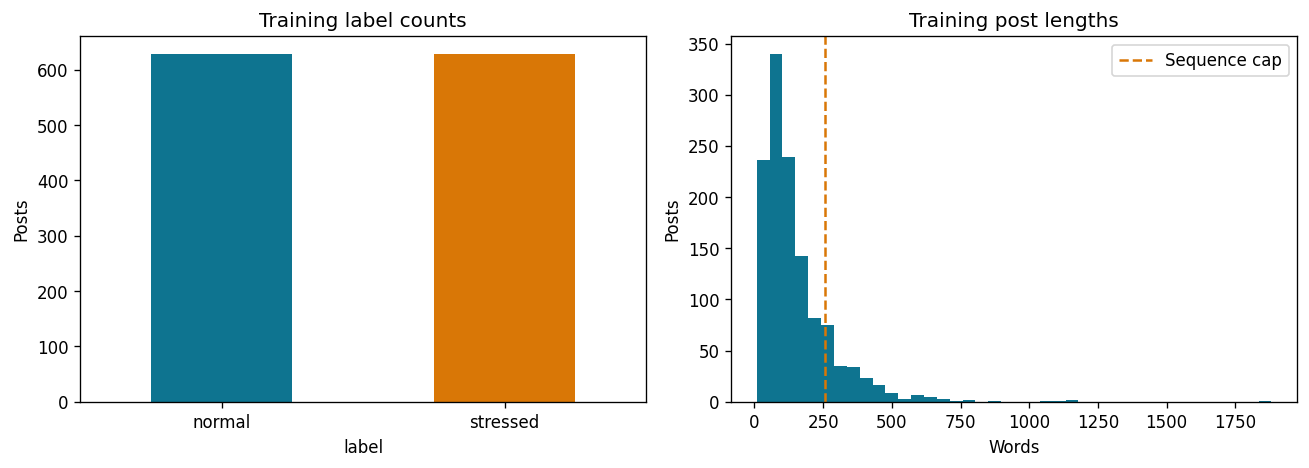

Sequence length: 256
Training posts truncated: 15.0%
Vocabulary size including padding/OOV: 9992
Input shapes: (1257, 256) (269, 256) (270, 256)


In [5]:
lengths = train_df["text"].str.split().str.len()
SEQUENCE_LENGTH = min(MAX_LENGTH_CAP, max(16, int(np.ceil(np.percentile(lengths, 95)))))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
train_df["label"].value_counts().reindex(["normal", "stressed"]).plot.bar(
    ax=axes[0], color=["#0e7490", "#d97706"], rot=0
)
axes[0].set(title="Training label counts", ylabel="Posts")
axes[1].hist(lengths, bins=40, color="#0e7490")
axes[1].axvline(SEQUENCE_LENGTH, color="#d97706", linestyle="--", label="Sequence cap")
axes[1].set(title="Training post lengths", xlabel="Words", ylabel="Posts")
axes[1].legend()
fig.tight_layout()
fig.savefig(ARTIFACTS / "training_data_overview.png", dpi=160)
plt.show()
print("Sequence length:", SEQUENCE_LENGTH)
print(f"Training posts truncated: {(lengths > SEQUENCE_LENGTH).mean():.1%}")

vectorizer = layers.TextVectorization(
    max_tokens=MAX_TOKENS, standardize=None, split="whitespace",
    output_mode="int", output_sequence_length=SEQUENCE_LENGTH,
    name="text_vectorization",
)
vectorizer.adapt(tf.constant(train_df["text"].tolist()))
VOCAB_SIZE = len(vectorizer.get_vocabulary())

def encode(part):
    x = vectorizer(tf.constant(part["text"].tolist())).numpy()
    y = part["target"].to_numpy(dtype="float32")
    return x, y

x_train, y_train = encode(train_df)
x_val, y_val = encode(val_df)
x_test, y_test = encode(test_df)  # transform only; no test-dependent choices
print("Vocabulary size including padding/OOV:", VOCAB_SIZE)
print("Input shapes:", x_train.shape, x_val.shape, x_test.shape)

def make_dataset(x, y=None, training=False):
    values = x if y is None else (x, y)
    dataset = tf.data.Dataset.from_tensor_slices(values)
    if training:
        dataset = dataset.shuffle(len(x), seed=SEED, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 2
    return dataset.batch(BATCH_SIZE).with_options(options).prefetch(1)

train_ds = make_dataset(x_train, y_train, training=True)
val_ds = make_dataset(x_val, y_val)
test_ds = make_dataset(x_test, y_test)

## 6. TF-IDF + logistic-regression baseline
TF-IDF weights informative words and two-word phrases. Logistic regression learns a
linear decision boundary. It is an inexpensive, strong comparison on a small text
dataset. The baseline and LSTM use identical splits. A more complex model is not
automatically more accurate. Hyperparameters below are fixed, not test-tuned.

In [6]:
baseline = make_pipeline(
    TfidfVectorizer(max_features=10000, ngram_range=(1, 2), min_df=2,
                    sublinear_tf=True, lowercase=False),
    LogisticRegression(C=1.0, solver="liblinear", max_iter=1000, random_state=SEED),
)
baseline.fit(train_df["text"], y_train)
val_baseline_probability = baseline.predict_proba(val_df["text"])[:, 1]
print("Baseline validation F1:", round(f1_score(y_val, val_baseline_probability >= THRESHOLD), 4))

Baseline validation F1: 0.943


## 7. Build the LSTM
**Architecture:** integer tokens → 64-dimensional embeddings → spatial dropout (0.2)
→ LSTM (64 units) → dense ReLU (32) → dropout (0.5) → sigmoid (1).
The embedding vectors are learned from this dataset. `mask_zero=True` tells the LSTM
to ignore padded positions. The final hidden state summarizes the sequence.
The output is a model score for the stressed label, not a calibrated clinical probability.

An LSTM maintains a memory state c_t and a hidden state h_t. Its gates choose what to
forget, store and expose (⊙ is elementwise multiplication):

$$f_t=\sigma(W_f[h_{t-1},x_t]+b_f),\quad i_t=\sigma(W_i[h_{t-1},x_t]+b_i)$$
$$\tilde c_t=\tanh(W_c[h_{t-1},x_t]+b_c),\quad c_t=f_t\odot c_{t-1}+i_t\odot\tilde c_t$$
$$o_t=\sigma(W_o[h_{t-1},x_t]+b_o),\quad h_t=o_t\odot\tanh(c_t)$$

These additive memory updates can carry information across words more effectively
than a simple recurrent network. They do not guarantee understanding or prevent all
vanishing-gradient problems. The loss is binary cross-entropy:
$$L=-\frac{1}{N}\sum_{i=1}^{N}[y_i\log p_i+(1-y_i)\log(1-p_i)].$$

In [7]:
model = keras.Sequential([
    keras.Input(shape=(SEQUENCE_LENGTH,), dtype="int64", name="token_ids"),
    layers.Embedding(VOCAB_SIZE, EMBEDDING_DIM, mask_zero=True, name="embedding"),
    layers.SpatialDropout1D(0.2),
    layers.LSTM(LSTM_UNITS, name="lstm"),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid", name="stressed_score"),
], name="stress_lstm")
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001, clipnorm=1.0),
    loss="binary_crossentropy",
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy"), keras.metrics.AUC(name="auc")],
)
model.summary()

Model: "stress_lstm"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 256, 64)        │       639,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 256, 64)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)         

## 8. Train and select the best epoch
Adam updates the parameters. Dropout regularizes the model; gradient clipping limits
unusually large updates. Early stopping watches validation loss with patience 4 and
restores the best weights. The test set is never passed to model.fit(). Since classes
are nearly balanced, no resampling or class weights are needed.

In [8]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True, verbose=1),
    keras.callbacks.ModelCheckpoint(str(ARTIFACTS / "best_lstm.keras"),
                                    monitor="val_loss", save_best_only=True),
    keras.callbacks.CSVLogger(str(ARTIFACTS / "training_history.csv")),
    keras.callbacks.TerminateOnNaN(),
]
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks, verbose=2)
BEST_EPOCH = int(np.argmin(history.history["val_loss"]) + 1)
print("Best epoch by validation loss:", BEST_EPOCH)

/workspace/scratch/0b9e7ba06320/.mlvenv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
Epoch 1/20
40/40 - 3s - 72ms/step - accuracy: 0.5481 - auc: 0.5755 - loss: 0.6868 - val_accuracy: 0.6989 - val_auc: 0.8686 - val_loss: 0.6348
Epoch 2/20
40/40 - 1s - 37ms/step - accuracy: 0.8799 - auc: 0.9104 - loss: 0.4190 - val_accuracy: 0.9182 - val_auc: 0.9598 - val_loss: 0.2647
Epoch 3/20
40/40 - 2s - 40ms/step - accuracy: 0.9531 - auc: 0.9573 - loss: 0.2219 - val_accuracy: 0.8885 - val_auc: 0.9647 - val_loss: 0.3531
Epoch 4/20
40/40 - 2s - 38ms/step - accuracy: 0.9602 - auc: 0.9625 - loss: 0.1979 - val_accuracy: 0.9294 - val_auc: 0.9885 - val_loss: 0.1836
Epoch 5/20
40/40 - 2s - 44ms/step - accuracy: 0.9745 - auc: 0.9768 - loss: 0

## 9. Learning curves
Decreasing training loss with increasing validation loss is evidence of overfitting.
Early stopping restores an earlier epoch; it does not make the dataset larger or
eliminate sampling uncertainty.

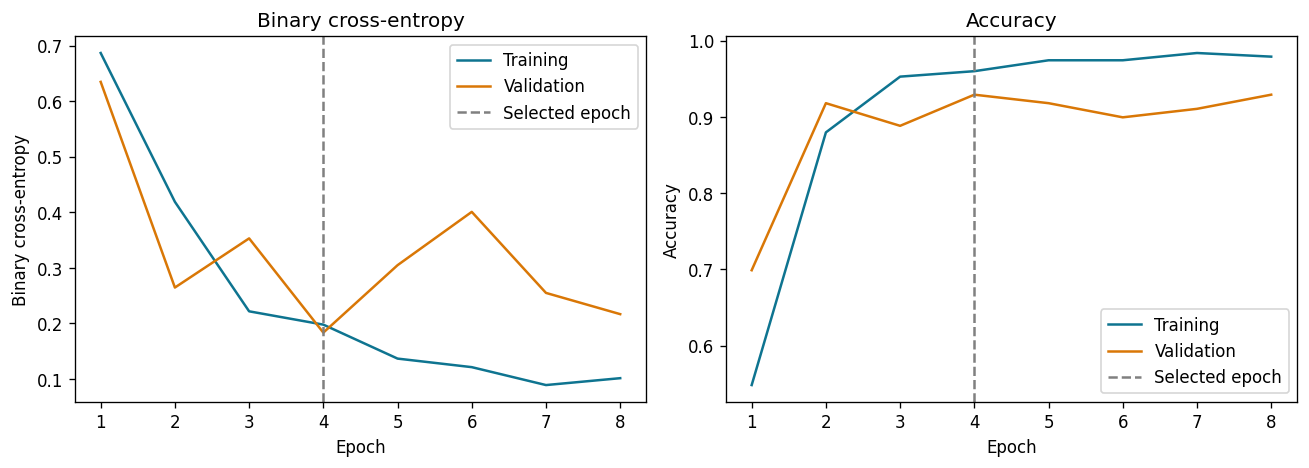

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
epoch_numbers = np.arange(1, len(history.history["loss"]) + 1)
for ax, metric, title in zip(axes, ["loss", "accuracy"], ["Binary cross-entropy", "Accuracy"]):
    ax.plot(epoch_numbers, history.history[metric], label="Training", color="#0e7490")
    ax.plot(epoch_numbers, history.history["val_" + metric], label="Validation", color="#d97706")
    ax.axvline(BEST_EPOCH, linestyle="--", color="gray", label="Selected epoch")
    ax.set(xlabel="Epoch", ylabel=title, title=title)
    ax.legend()
fig.tight_layout()
fig.savefig(ARTIFACTS / "learning_curves.png", dpi=160)
plt.show()

## 10. Final held-out evaluation
Both models use a fixed threshold of 0.5. We report accuracy, stressed-class precision,
recall and F1, macro-F1, ROC-AUC and average precision (AP). AP summarizes the
precision-recall ranking and is not the same as trapezoidal PR-AUC. The confusion
matrix shows true labels in rows and predictions in columns.

Precision = TP/(TP+FP), recall = TP/(TP+FN), F1 = 2PR/(P+R).
A false negative is a stressed-labeled post predicted normal; a false positive is the
reverse. Do not repeatedly adjust the model based on these test results. Further tuning
requires validation data and a fresh final test evaluation strategy.

                              accuracy  precision_stressed  recall_stressed  f1_stressed  macro_f1  roc_auc  average_precision
model                                                                                                                         
TF-IDF + Logistic Regression    0.9333              0.9398           0.9259       0.9328    0.9333   0.9832             0.9838
LSTM                            0.9259              0.9137           0.9407       0.9270    0.9259   0.9747             0.9714

LSTM classification report:

              precision    recall  f1-score   support

      normal     0.9389    0.9111    0.9248       135
    stressed     0.9137    0.9407    0.9270       135

    accuracy                         0.9259       270
   macro avg     0.9263    0.9259    0.9259       270
weighted avg     0.9263    0.9259    0.9259       270



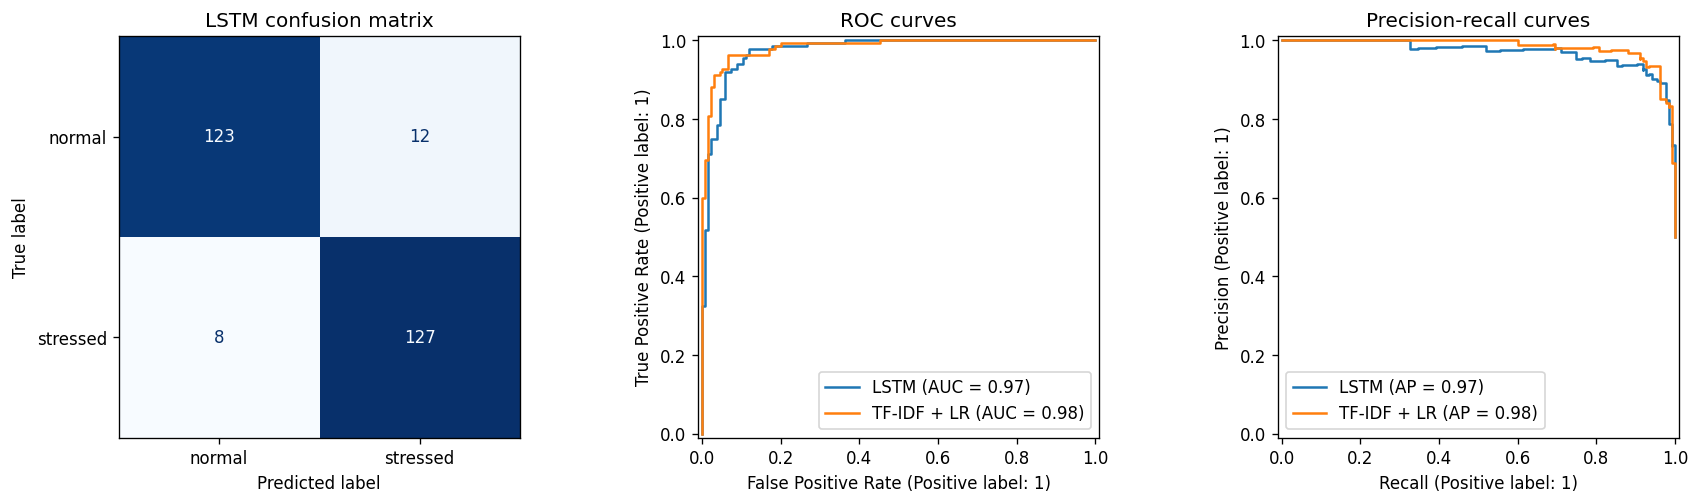

In [10]:
def metric_row(name, target, probability):
    predicted = (probability >= THRESHOLD).astype(int)
    return {"model": name,
            "accuracy": float(accuracy_score(target, predicted)),
            "precision_stressed": float(precision_score(target, predicted, zero_division=0)),
            "recall_stressed": float(recall_score(target, predicted, zero_division=0)),
            "f1_stressed": float(f1_score(target, predicted, zero_division=0)),
            "macro_f1": float(f1_score(target, predicted, average="macro", zero_division=0)),
            "roc_auc": float(roc_auc_score(target, probability)),
            "average_precision": float(average_precision_score(target, probability))}

lstm_probability = model.predict(make_dataset(x_test), verbose=0).ravel()
baseline_probability = baseline.predict_proba(test_df["text"])[:, 1]
lstm_predicted = (lstm_probability >= THRESHOLD).astype(int)
rows = [metric_row("TF-IDF + Logistic Regression", y_test, baseline_probability),
        metric_row("LSTM", y_test, lstm_probability)]
comparison = pd.DataFrame(rows).set_index("model")
print(comparison.round(4).to_string())
print("\nLSTM classification report:\n")
print(classification_report(y_test, lstm_predicted, labels=[0, 1],
                            target_names=["normal", "stressed"], digits=4, zero_division=0))
comparison.to_csv(ARTIFACTS / "model_comparison.csv")
report = classification_report(y_test, lstm_predicted, labels=[0, 1],
                               target_names=["normal", "stressed"], output_dict=True, zero_division=0)
metrics = {"test_rows": int(len(test_df)), "threshold": THRESHOLD,
           "best_epoch": BEST_EPOCH, "epochs_completed": len(epoch_numbers),
           "models": rows, "lstm_classification_report": report}
(ARTIFACTS / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
predictions = test_df[["source_row", "label"]].copy()
predictions["lstm_stressed_score"] = lstm_probability
predictions["lstm_predicted_label"] = np.where(lstm_predicted == 1, "stressed", "normal")
predictions["baseline_stressed_score"] = baseline_probability
predictions.to_csv(ARTIFACTS / "test_predictions.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
ConfusionMatrixDisplay.from_predictions(y_test, lstm_predicted, labels=[0, 1],
    display_labels=["normal", "stressed"], cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("LSTM confusion matrix")
for name, probability in [("LSTM", lstm_probability), ("TF-IDF + LR", baseline_probability)]:
    RocCurveDisplay.from_predictions(y_test, probability, name=name, ax=axes[1])
    PrecisionRecallDisplay.from_predictions(y_test, probability, name=name, ax=axes[2])
axes[1].set_title("ROC curves")
axes[2].set_title("Precision-recall curves")
fig.tight_layout()
fig.savefig(ARTIFACTS / "test_evaluation.png", dpi=160)
plt.show()

## 11. Save and reload for inference
The exported .keras model bundles vocabulary, padding/truncation and LSTM weights.
It expects text normalized with the same clean_text() function. Save that function
and metadata alongside it; saving only the weights is not enough for reliable reuse.
A round-trip check verifies that saving/loading preserves predictions.

In [11]:
text_input = keras.Input(shape=(), dtype=tf.string, name="cleaned_text")
text_model = keras.Model(text_input, model(vectorizer(text_input)), name="text_to_stress_score")
text_model.save(ARTIFACTS / "stress_text_model.keras")
reloaded = keras.models.load_model(ARTIFACTS / "stress_text_model.keras", compile=False)
probe = tf.constant(val_df["text"].iloc[:8].tolist())
np.testing.assert_allclose(text_model(probe, training=False).numpy(),
                           reloaded(probe, training=False).numpy(), atol=1e-6, rtol=1e-5)
print("Save/reload prediction check: PASS")

def predict_text(texts):
    if isinstance(texts, str):
        texts = [texts]
    if not texts or any(not isinstance(text, str) for text in texts):
        raise ValueError("Provide a string or a non-empty list of strings.")
    cleaned = [clean_text(text) for text in texts]
    if any(not text for text in cleaned):
        raise ValueError("Input is empty after cleaning. Enter meaningful text.")
    scores = reloaded(tf.constant(cleaned), training=False).numpy().ravel()
    return pd.DataFrame({"text": texts,
                         "predicted_label": np.where(scores >= THRESHOLD, "stressed", "normal"),
                         "stressed_score": scores,
                         "truncated": [len(text.split()) > SEQUENCE_LENGTH for text in cleaned]})

# Invented demonstration sentences; these are NOT additional evaluation examples.
print(predict_text([
    "I feel overwhelmed by deadlines and I cannot stop worrying.",
    "I had a relaxing afternoon and enjoyed cooking dinner.",
]).to_string(index=False))

Save/reload prediction check: PASS
                                                       text predicted_label  stressed_score  truncated
I feel overwhelmed by deadlines and I cannot stop worrying.        stressed        0.603273      False
     I had a relaxing afternoon and enjoyed cooking dinner.          normal        0.429584      False


## 12. Export artifacts and interpret the project
The output ZIP includes the saved model, metrics, plots, split IDs, configuration and
environment versions. It excludes the original posts. Keep raw text out of a public
repository unless you have verified its source, license and permission to redistribute.
The dataset's source, collection method and annotation protocol were not supplied.

Use the measured results, including cases where the baseline wins. A single small
random test split cannot establish clinical reliability, generalization to another
population, robustness to sarcasm or fairness. The model may learn topic/source cues
instead of stress itself. Future work: inspect errors locally, obtain a documented
dataset, evaluate author-disjoint splits, compare repeated seeds, and test pretrained
embeddings or a bidirectional LSTM using validation data only.

In [12]:
config = {"seed": SEED, "label_map": LABEL_MAP, "threshold": THRESHOLD,
          "max_tokens": MAX_TOKENS, "vocabulary_size": VOCAB_SIZE,
          "sequence_length": SEQUENCE_LENGTH, "embedding_dim": EMBEDDING_DIM,
          "lstm_units": LSTM_UNITS, "batch_size": BATCH_SIZE, "maximum_epochs": EPOCHS,
          "best_epoch": BEST_EPOCH, "parameters": model.count_params(),
          "dataset_sha256": DATA_SHA256, "split_sizes": {k: len(v) for k, v in parts.items()},
          "preprocessing": "clean_text v1; see preprocessing.py",
          "training_truncation_fraction": float((lengths > SEQUENCE_LENGTH).mean()),
          "python": platform.python_version(), "tensorflow": tf.__version__,
          "keras": keras.__version__, "numpy": np.__version__, "pandas": pd.__version__,
          "scikit_learn": sklearn.__version__, "device": "GPU" if tf.config.list_physical_devices("GPU") else "CPU"}
(ARTIFACTS / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
# This source is exactly the clean_text function above, included for standalone reuse.
PREPROCESSING_SOURCE = '"""Shared deterministic preprocessing for training and inference."""\nimport re\nimport unicodedata\n\ndef clean_text(text):\n    """Deterministic normalization shared by training and inference."""\n    text = unicodedata.normalize("NFKC", str(text)).lower()\n    text = text.replace("’", "\'").replace("‘", "\'")\n    text = re.sub(r"https?://\\S+|www\\.\\S+", " url ", text)\n    text = re.sub(r"\\b[\\w.+-]+@[\\w.-]+\\.[a-z]{2,}\\b", " email ", text)\n    text = re.sub(r"(?<!\\w)(?:u/|@)[\\w-]+", " user ", text)\n    text = re.sub(r"[^\\w\\s\']", " ", text)\n    return re.sub(r"\\s+", " ", text).strip()\n'
(ARTIFACTS / "preprocessing.py").write_text(PREPROCESSING_SOURCE, encoding="utf-8")
PREDICT_SOURCE = '"""Predict a dataset label with a saved LSTM. Run: python predict.py --text \'...\'."""\nimport argparse\nimport json\nfrom pathlib import Path\nimport tensorflow as tf\nfrom preprocessing import clean_text\n\n\ndef predict(text, artifact_dir):\n    cleaned = clean_text(text)\n    if not cleaned:\n        raise ValueError("Input is empty after cleaning. Enter meaningful text.")\n    artifact_dir = Path(artifact_dir)\n    config = json.loads((artifact_dir / "config.json").read_text(encoding="utf-8"))\n    model = tf.keras.models.load_model(artifact_dir / "stress_text_model.keras", compile=False)\n    score = float(model(tf.constant([cleaned]), training=False).numpy().ravel()[0])\n    return {"predicted_label": "stressed" if score >= config["threshold"] else "normal",\n            "stressed_score": score,\n            "truncated": len(cleaned.split()) > config["sequence_length"]}\n\n\nif __name__ == "__main__":\n    base = Path(__file__).resolve().parent\n    default_dir = base / "artifacts" if (base / "artifacts").exists() else base\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--text", required=True, help="Text to classify")\n    parser.add_argument("--artifacts", default=str(default_dir), help="Saved model/config folder")\n    args = parser.parse_args()\n    print(json.dumps(predict(args.text, args.artifacts), indent=2))\n'
(ARTIFACTS / "predict.py").write_text(PREDICT_SOURCE, encoding="utf-8")
archive = shutil.make_archive("stress_lstm_artifacts", "zip", ARTIFACTS)
print("Saved:", archive)
print("LSTM test accuracy:", f"{comparison.loc['LSTM', 'accuracy']:.2%}")
print("LSTM test stressed F1:", f"{comparison.loc['LSTM', 'f1_stressed']:.4f}")
print("Use the Colab Files panel to download stress_lstm_artifacts.zip.")
# Optional in Colab: uncomment the next two lines to download immediately.
# from google.colab import files
# files.download(archive)

Saved: /workspace/scratch/0b9e7ba06320/stress-text-lstm/stress_lstm_artifacts.zip
LSTM test accuracy: 92.59%
LSTM test stressed F1: 0.9270
Use the Colab Files panel to download stress_lstm_artifacts.zip.


## References
- [Keras LSTM layer](https://keras.io/api/layers/recurrent_layers/lstm/)
- [TextVectorization](https://keras.io/api/layers/preprocessing_layers/text/text_vectorization/)
- [Masking and padding](https://www.tensorflow.org/guide/keras/understanding_masking_and_padding)
- [Early stopping](https://keras.io/api/callbacks/early_stopping/)
- [Avoiding data leakage](https://scikit-learn.org/stable/common_pitfalls.html)
- [TensorFlow text-classification tutorial](https://www.tensorflow.org/tutorials/keras/text_classification)